In [1]:
from nupack import *

# =========================================================
# model
# =========================================================
# PEN toolbox / Nt.BstNBI reactions are often run near 37-45 C.
# Change celsius / salt conditions here to match your experiment.

model = Model(
    material='dna',
    celsius=38.5,
    sodium=0.050,
    magnesium=0.007,

)

# =========================================================
# sequences from the PEN toolbox Oligator table
# =========================================================
# Table notation:
#   T1  A*A*CAGACTCGA-AACAGACTCGA-3'P
#   T2  G*C*ATGACTCAT-AACAGACTCGA-3'P
#   T3  T*T*ACTCGAAACAGACT-GCATGACTCAT-3'P
#   alpha  TCGAGTCTGTT
#   beta   ATGAGTCATGC
#   Inh    AGTCTGTTTCGAGTAA
# NUPACK receives only unmodified DNA bases; chemical modifications are
# represented by the names/comments above, not by the sequence strings.

seq = {
    'T1': 'AACAGACTCGAAACAGACTCGA',
    'T2': 'GCATGACTCATAACAGACTCGA',
    'T3': 'TTACTCGAAACAGACTCGA',
    'alpha': 'TCGAGTCTGTT',
    'beta': 'ATGAGTCATGC',
    'Inh': 'AGTCTGTTTCGAGTAA',
}

T1 = Strand(seq['T1'], name='Template1')
T2 = Strand(seq['T2'], name='Template2')
T3 = Strand(seq['T3'], name='Template3')
alpha = Strand(seq['alpha'], name='A')
beta = Strand(seq['beta'], name='B')
Inh = Strand(seq['Inh'], name='Inh')


In [9]:
# =========================================================
# tube analysis: all complexes up to 3 strands
# =========================================================
# Concentrations are placeholders. Edit them to match the PEN experiment.
# NUPACK concentration solver requires positive values, so absent species use 1 fM.

concentration = {
    T1: 6e-8,
    alpha: 2e-8,
    Inh: 8e-8,
}

pen_tube = Tube(
    strands=concentration,
    complexes=SetSpec(max_size=2),
    name='PEN_toolbox_oligator',
)

tube_results = tube_analysis(
    tubes=[pen_tube],
    model=model,
    compute=['mfe', 'pairs'],
)

tube_results


Result(tubes={<Tube PEN_toolbox_oligator>: <nupack.analysis.TubeResult object at 0x7f1c9d625450>}, complexes=<nupack.analysis.ComplexDict object at 0x7f1c9d624cd0>)

In [10]:
import pandas as pd

# TubeResultを取得
result = tube_results[pen_tube]

rows = []

# 全複合体について
for complex_obj, conc in result.complex_concentrations.items():
    rows.append({
        "Complex": str(complex_obj),
        "Concentration (M)": conc
    })

# DataFrame化
df = pd.DataFrame(rows)

# 濃度の高い順に並べ替え
df = df.sort_values("Concentration (M)", ascending=False)

# CSV出力
df.to_csv("1_2.csv", index=False)

print(df.head())

                     Complex  Concentration (M)
6  <Complex (Inh+Template1)>       5.929479e-08
4            <Complex (Inh)>       2.070470e-08
0              <Complex (A)>       1.968593e-08
7      <Complex (Template1)>       3.915049e-10
3    <Complex (A+Template1)>       3.137021e-10


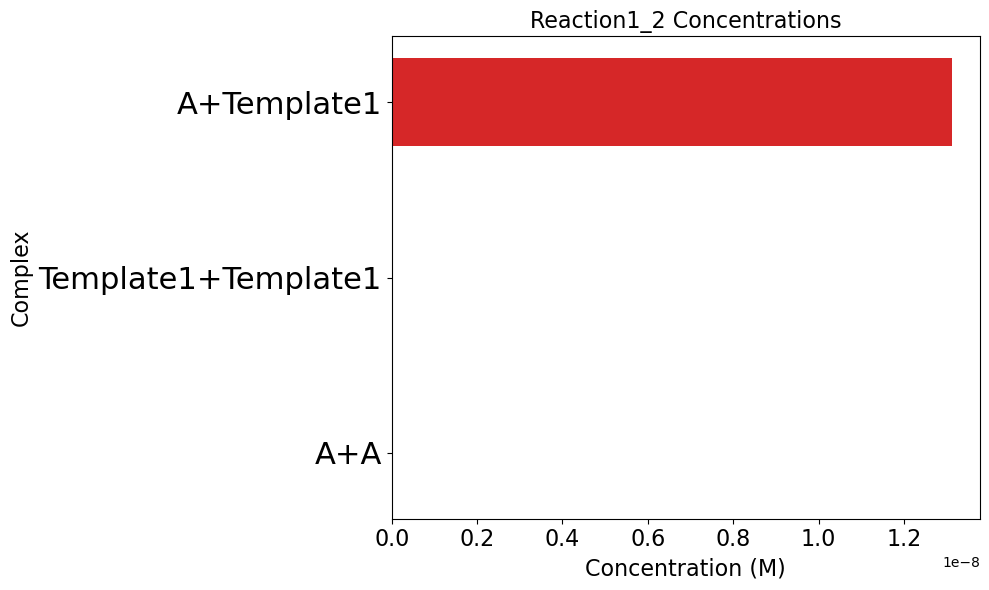

In [35]:
import matplotlib.pyplot as plt

# ==========================================
# Concentration結果を取得
# ==========================================
tube = tube_results["PEN_toolbox_oligator"]

data = []
for comp, result in tube.complex_concentrations.items():
    if len(comp.strands) >= 2:
        # 複合体名
        name = "+".join([s.name for s in comp.strands])

        # 平衡濃度 (M)
        conc = result

        data.append((name, conc))

# 濃度の高い順に並べる
data.sort(key=lambda x: x[1], reverse=True)

# 上位10件
top10 = data[:3]

names = [x[0] for x in top10]
concs = [x[1] for x in top10]

# ==========================================
# グラフ
# ==========================================
plt.figure(figsize=(10,6))
plt.barh(names, concs, height=0.5, color="#d62728")
plt.yticks(fontsize=22)
plt.xticks(fontsize=16)
plt.gca().invert_yaxis()   # 一番上が最大濃度
plt.xlabel("Concentration (M)",fontsize=16)
plt.ylabel("Complex",fontsize=16)
plt.title("Reaction1_2 Concentrations",fontsize=16)
plt.tight_layout()
plt.show()

In [11]:
# =========================================================
# tube analysis: all complexes up to 3 strands
# =========================================================
# Concentrations are placeholders. Edit them to match the PEN experiment.
# NUPACK concentration solver requires positive values, so absent species use 1 fM.

concentration = {
    T1: 6e-8,
    alpha: 2e-8,
}

pen_tube = Tube(
    strands=concentration,
    complexes=SetSpec(max_size=2),
    name='PEN_toolbox_oligator',
)

tube_results = tube_analysis(
    tubes=[pen_tube],
    model=model,
    compute=['mfe', 'pairs'],
)

tube_results


Result(tubes={<Tube PEN_toolbox_oligator>: <nupack.analysis.TubeResult object at 0x7f1c9d842780>}, complexes=<nupack.analysis.ComplexDict object at 0x7f1c9d841cd0>)

In [8]:
import pandas as pd

# TubeResultを取得
result = tube_results[pen_tube]

rows = []

# 全複合体について
for complex_obj, conc in result.complex_concentrations.items():
    rows.append({
        "Complex": str(complex_obj),
        "Concentration (M)": conc
    })

# DataFrame化
df = pd.DataFrame(rows)

# 濃度の高い順に並べ替え
df = df.sort_values("Concentration (M)", ascending=False)

# CSV出力
df.to_csv("1_1.csv", index=False)

print(df.head())

                           Complex  Concentration (M)
3            <Complex (Template1)>       4.687691e-08
2          <Complex (A+Template1)>       1.312246e-08
0                    <Complex (A)>       6.877521e-09
4  <Complex (Template1+Template1)>       3.147154e-13
1                  <Complex (A+A)>       1.009107e-14


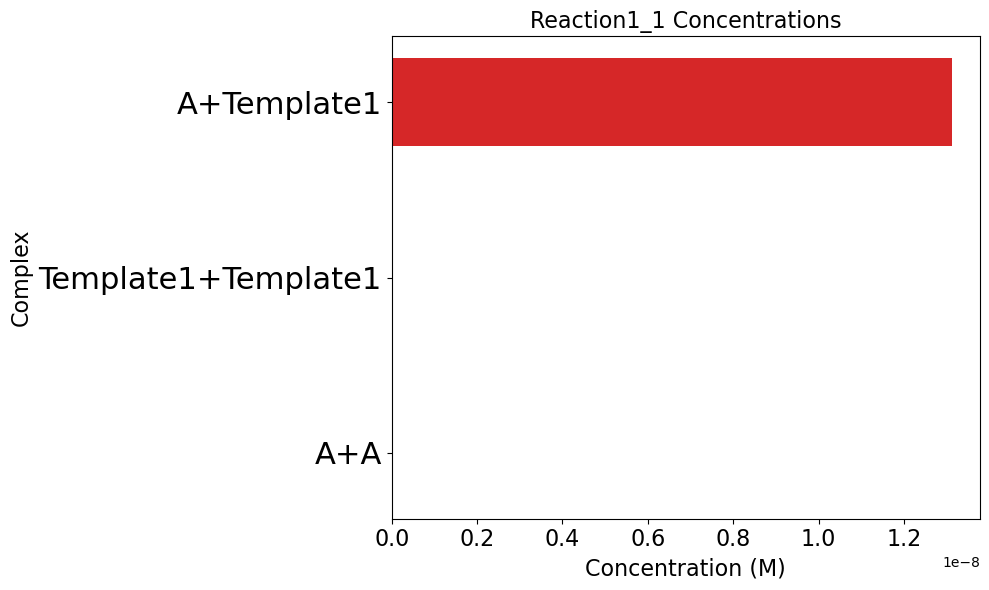

In [34]:
import matplotlib.pyplot as plt

# ==========================================
# Concentration結果を取得
# ==========================================
tube = tube_results["PEN_toolbox_oligator"]

data = []
for comp, result in tube.complex_concentrations.items():
    if len(comp.strands) >= 2:
        # 複合体名
        name = "+".join([s.name for s in comp.strands])

        # 平衡濃度 (M)
        conc = result

        data.append((name, conc))

# 濃度の高い順に並べる
data.sort(key=lambda x: x[1], reverse=True)

# 上位10件
top10 = data[:3]

names = [x[0] for x in top10]
concs = [x[1] for x in top10]

# ==========================================
# グラフ
# ==========================================
plt.figure(figsize=(10,6))
plt.barh(names, concs, height=0.5, color="#d62728")
plt.yticks(fontsize=22)
plt.xticks(fontsize=16)
plt.gca().invert_yaxis()   # 一番上が最大濃度
plt.xlabel("Concentration (M)",fontsize=16)
plt.ylabel("Complex",fontsize=16)
plt.title("Reaction1_1 Concentrations",fontsize=16)
plt.tight_layout()
plt.show()

In [13]:
# =========================================================
# tube analysis: all complexes up to 3 strands
# =========================================================
# Concentrations are placeholders. Edit them to match the PEN experiment.
# NUPACK concentration solver requires positive values, so absent species use 1 fM.

concentration = {

    T2: 5e-9,
    alpha: 2e-8,
    beta: 2e-8,
}

pen_tube = Tube(
    strands=concentration,
    complexes=SetSpec(max_size=2),
    name='PEN_toolbox_oligator',
)

tube_results = tube_analysis(
    tubes=[pen_tube],
    model=model,
    compute=['mfe', 'pairs'],
)

tube_results


Result(tubes={<Tube PEN_toolbox_oligator>: <nupack.analysis.TubeResult object at 0x7f1c9d842c40>}, complexes=<nupack.analysis.ComplexDict object at 0x7f1c9d842520>)

In [14]:
import pandas as pd

# TubeResultを取得
result = tube_results[pen_tube]

rows = []

# 全複合体について
for complex_obj, conc in result.complex_concentrations.items():
    rows.append({
        "Complex": str(complex_obj),
        "Concentration (M)": conc
    })

# DataFrame化
df = pd.DataFrame(rows)

# 濃度の高い順に並べ替え
df = df.sort_values("Concentration (M)", ascending=False)

# CSV出力
df.to_csv("2.csv", index=False)

print(df.head())

                   Complex  Concentration (M)
4            <Complex (B)>       1.947807e-08
0            <Complex (A)>       1.749056e-08
3  <Complex (A+Template2)>       2.509252e-09
7    <Complex (Template2)>       1.972813e-09
6  <Complex (B+Template2)>       5.179303e-10


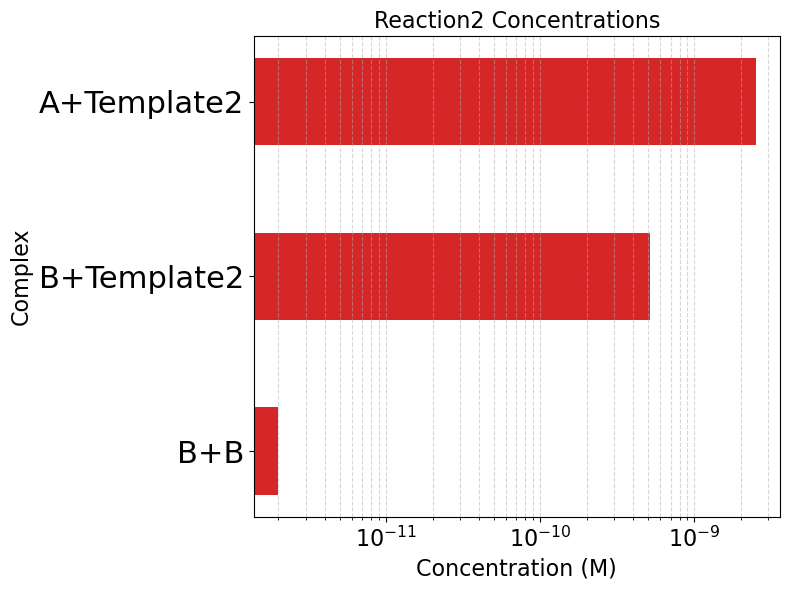

In [58]:
import matplotlib.pyplot as plt

# ==========================================
# Concentration結果を取得
# ==========================================
tube = tube_results["PEN_toolbox_oligator"]

data = []
for comp, result in tube.complex_concentrations.items():
    if len(comp.strands) >= 2:
        # 複合体名
        name = "+".join([s.name for s in comp.strands])

        # 平衡濃度 (M)
        conc = result

        data.append((name, conc))

# 濃度の高い順に並べる
data.sort(key=lambda x: x[1], reverse=True)

# 上位10件
top10 = data[:3]

names = [x[0] for x in top10]
concs = [x[1] for x in top10]

# ==========================================
# グラフ
# ==========================================
plt.figure(figsize=(8,6))
plt.barh(names, concs, height=0.5,color="#d62728")
plt.yticks(fontsize=22)
plt.xticks(fontsize=16)
plt.xscale("log")
plt.grid(axis="x", which="both", linestyle="--", alpha=0.5)
plt.gca().invert_yaxis()   # 一番上が最大濃度
plt.xlabel("Concentration (M)",fontsize=16)
plt.ylabel("Complex",fontsize=16)
plt.title("Reaction2 Concentrations",fontsize=16)
plt.tight_layout()
plt.show()

In [15]:
# =========================================================
# tube analysis: all complexes up to 3 strands
# =========================================================
# Concentrations are placeholders. Edit them to match the PEN experiment.
# NUPACK concentration solver requires positive values, so absent species use 1 fM.

concentration = {
    T3: 9e-8,
    beta: 2e-8,
    Inh: 8e-8,
}

pen_tube = Tube(
    strands=concentration,
    complexes=SetSpec(max_size=2),
    name='PEN_toolbox_oligator',
)

tube_results = tube_analysis(
    tubes=[pen_tube],
    model=model,
    compute=['mfe', 'pairs'],
)

tube_results


Result(tubes={<Tube PEN_toolbox_oligator>: <nupack.analysis.TubeResult object at 0x7f1c9d505d90>}, complexes=<nupack.analysis.ComplexDict object at 0x7f1c9d505370>)

In [16]:
import pandas as pd

# TubeResultを取得
result = tube_results[pen_tube]

rows = []

# 全複合体について
for complex_obj, conc in result.complex_concentrations.items():
    rows.append({
        "Complex": str(complex_obj),
        "Concentration (M)": conc
    })

# DataFrame化
df = pd.DataFrame(rows)

# 濃度の高い順に並べ替え
df = df.sort_values("Concentration (M)", ascending=False)

# CSV出力
df.to_csv("3.csv", index=False)

print(df.head())

                     Complex  Concentration (M)
6  <Complex (Inh+Template3)>       7.960126e-08
0              <Complex (B)>       1.999552e-08
7      <Complex (Template3)>       1.039839e-08
4            <Complex (Inh)>       3.987363e-10
1            <Complex (B+B)>       2.078965e-12


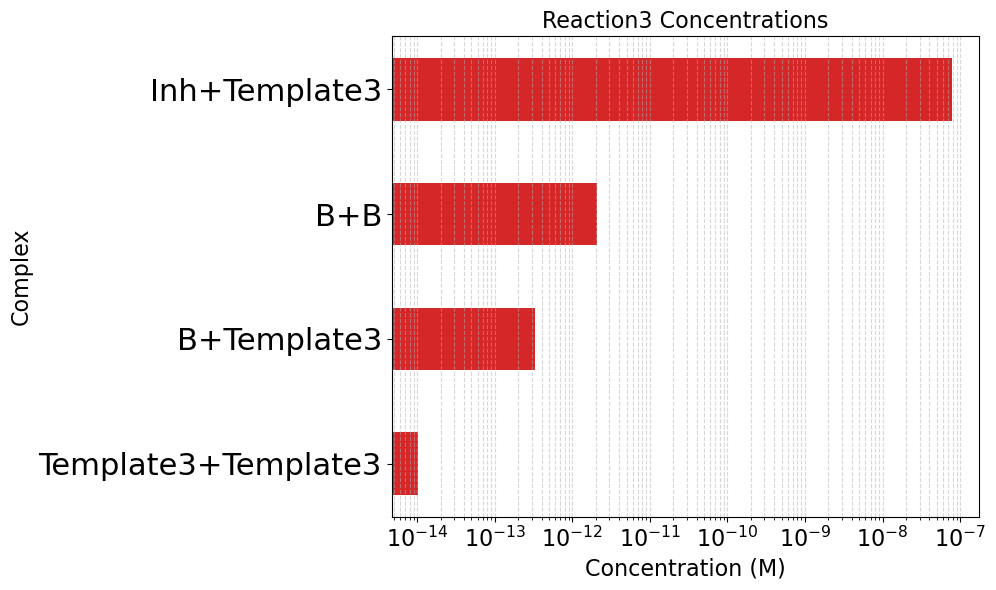

In [53]:
import matplotlib.pyplot as plt

# ==========================================
# Concentration結果を取得
# ==========================================
tube = tube_results["PEN_toolbox_oligator"]

data = []
for comp, result in tube.complex_concentrations.items():
    if len(comp.strands) >= 2:
        # 複合体名
        name = "+".join([s.name for s in comp.strands])

        # 平衡濃度 (M)
        conc = result

        data.append((name, conc))

# 濃度の高い順に並べる
data.sort(key=lambda x: x[1], reverse=True)

# 上位10件
top10 = data[:4]

names = [x[0] for x in top10]
concs = [x[1] for x in top10]

# ==========================================
# グラフ
# ==========================================
plt.figure(figsize=(10,6))
plt.barh(names, concs, height=0.5, color="#d62728")
plt.yticks(fontsize=22)
plt.xticks(fontsize=16)
plt.xscale("log")
plt.grid(axis="x", which="both", linestyle="--", alpha=0.5)
plt.gca().invert_yaxis()   # 一番上が最大濃度
plt.xlabel("Concentration (M)",fontsize=16)
plt.ylabel("Complex",fontsize=16)
plt.title("Reaction3 Concentrations",fontsize=16)
plt.tight_layout()
plt.show()